# DeiT III: Revenge of the ViT

**Paper:** H. Touvron, M. Cord, and H. Jégou, "DeiT III: Revenge of the ViT," in *European Conference on Computer Vision (ECCV)*, 2022. [arXiv:2204.07118](https://arxiv.org/abs/2204.07118)

**Summary:** DeiT III demonstrates that plain ViT with the right data augmentation and training recipe (3-Augmentation) outperforms complex self-supervised methods, challenging the notion that architectural complexity drives performance. LayerScale (γ init=1e-6) and mean pooling are the key architectural changes.

> 📄 **Paper:** Touvron, Cord & Jégou (2022). DeiT III: Revenge of the ViT. ECCV 2022.
> 🔗 **Link:** <https://arxiv.org/abs/2204.07118>
> 🧩 **Implementation:** `hale_core/nn/vision/vit/deit3.py` (reproduced in full in §4 - runs with plain PyTorch)

**How this notebook is organised:** 1. paper & idea · 2. architecture diagrams (Mermaid, ASCII, matplotlib) ·
3. key ideas · 4. the full architecture in pure PyTorch · 5. build & run · 6. parameters vs paper & gradient flow ·
7. equivalence with the library · 8. feature maps · references.

## 2. Architecture diagram

Colours: <span style="color:#d48806">■ input</span> · <span style="color:#1f77b4">■ stages</span> ·
<span style="color:#8e44ad">■ blocks / operations</span> · <span style="color:#c0392b">■ outputs</span>.
(Mermaid renders on GitHub, in JupyterLab ≥ 4.1 and VS Code; an ASCII and a matplotlib version follow.)

```mermaid
flowchart TB
  IN["image (B, 3, 224, 224)"]:::io --> PE["PatchEmbed 16×16"]:::stage --> CLS["[CLS] + pos-embed"]:::stage --> ENC["L × block with LayerScale"]:::stage --> NORM["LN"]:::block --> OUT
  subgraph TB["DeiT III block"]
    direction LR
    X["x"] --> LN1["LN"]:::block --> MSA["MSA"]:::block --> LS1["LayerScale γ₁"]:::block --> A1(("+ drop-path"))
    X --> A1 --> LN2["LN"]:::block --> MLP["MLP"]:::block --> LS2["LayerScale γ₂"]:::block --> A2(("+ drop-path"))
    A1 --> A2
  end
  ENC -.-> TB
  REC["recipe: 3-Augment, simple random crop, BCE loss, LayerScale"]:::block -.-> ENC
  OUT["BackboneOutput<br/>pooled_output (B, D)<br/>patch_tokens (B, N, D)<br/>feature_maps [(B, D, H/p, W/p)]"]:::out
  classDef io fill:#fff7e6,stroke:#d48806,color:#222
  classDef stage fill:#eaf2fb,stroke:#1f77b4,color:#222
  classDef block fill:#f1e6f8,stroke:#8e44ad,color:#222
  classDef out fill:#fdecea,stroke:#c0392b,color:#222
```

## Architecture Overview

```
Input Image [B, 3, H, W]
        │
        ▼  PatchEmbed (Conv2d, patch_size=16 or 14)
Patches [B, N, D]  + learned absolute pos_embed
        │
        ▼  ┌──────────────────────────────────────────────────────────────┐
           │  DeiT3Block × depth                                          │
           │  ┌────────────────────────────────────────────────────────┐  │
           │  │  attn_out = DeiT3Attn(LN(x))  ← Flash Attention       │  │
           │  │  x = x + LayerScale_γ₁(attn_out)   γ init = 1e-6     │  │
           │  │  x = x + LayerScale_γ₂(MLP(LN(x)))                   │  │
           │  └────────────────────────────────────────────────────────┘  │
           └──────────────────────────────────────────────────────────────┘
        │
        ▼  Final LayerNorm
        │
        ▼  Mean Pool over ALL patch tokens  (no CLS token)
        │
        ├──► pooled_output = mean(x, dim=1)   [B, D]
        └──► patch_tokens  = x                [B, N, D]
             feature_maps  = reshape → [B, D, H/p, W/p]
```

### DeiT I → II → III Evolution
| Feature | DeiT I (2020) | DeiT II (not official) | DeiT III (2022) |
|---------|---------------|------------------------|----------------|
| Architecture | Plain ViT | Plain ViT | Plain ViT + LayerScale |
| Pooling | CLS token | CLS token | Mean pool (no CLS) |
| LayerScale | No | No | Yes (γ init=1e-6) |
| Training | DeiT distillation | — | 3-Augmentation (no distillation) |
| Flash Attention | No | No | Yes (PyTorch ≥2.0) |
| Key insight | Distillation token | — | **Recipe > Architecture** |

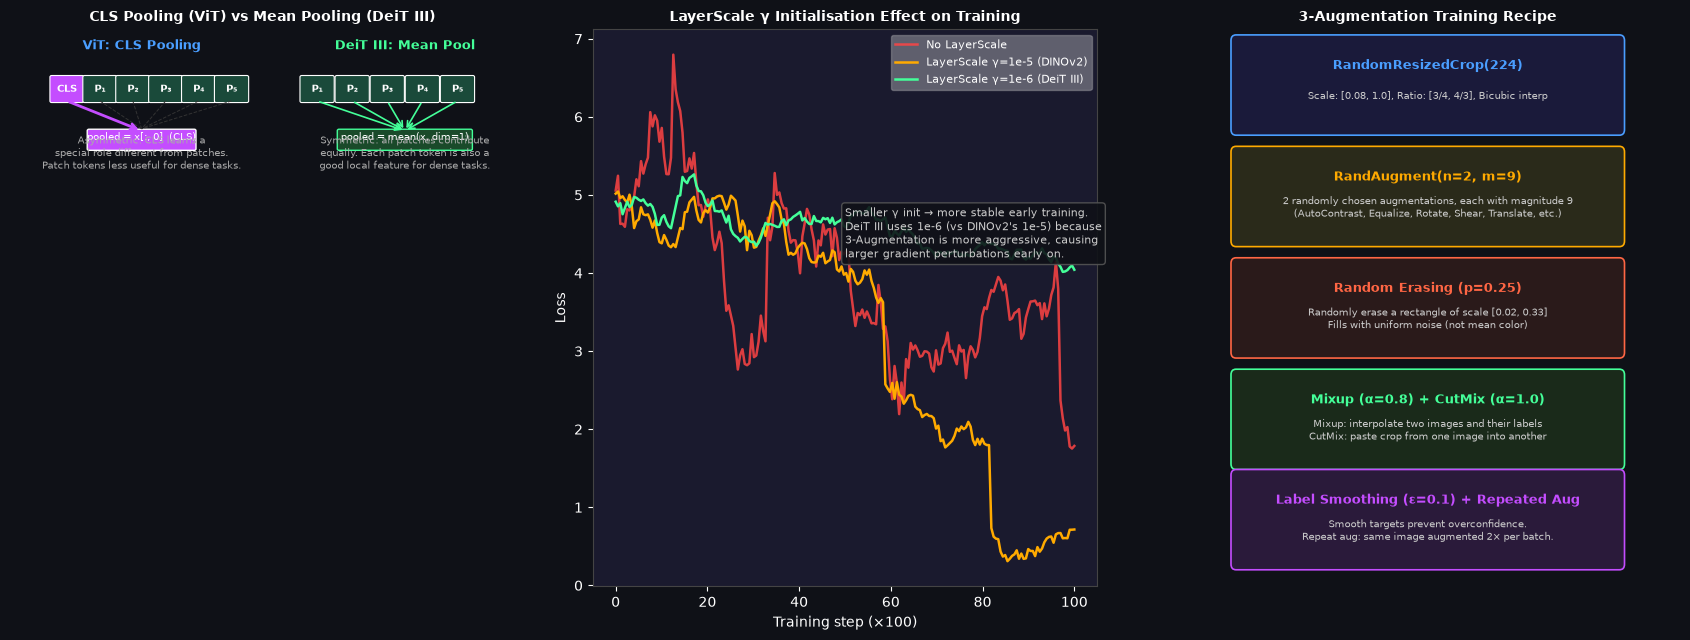

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch

fig, axes = plt.subplots(1, 3, figsize=(17, 6.5))
fig.patch.set_facecolor('#0f1117')

# ── Panel 1: Architecture comparison (CLS vs mean-pool) ──────────────────────
ax1 = axes[0]
ax1.set_facecolor('#0f1117')
ax1.set_xlim(-0.5, 11)
ax1.set_ylim(-1, 13)
ax1.axis('off')
ax1.set_title('CLS Pooling (ViT) vs Mean Pooling (DeiT III)', color='white', fontsize=10, fontweight='bold')

def draw_token(ax, x, y, label, color, h=0.6, w=0.7):
    b = FancyBboxPatch((x-w/2, y-h/2), w, h,
                        boxstyle='round,pad=0.04', facecolor=color,
                        edgecolor='white', linewidth=0.8)
    ax.add_patch(b)
    ax.text(x, y, label, ha='center', va='center', color='white',
            fontsize=7.5, fontweight='bold')

# Left: ViT CLS approach
ax1.text(2.5, 12.5, 'ViT: CLS Pooling', ha='center', color='#4a9eff', fontsize=9, fontweight='bold')
token_labels = ['CLS', 'P₁', 'P₂', 'P₃', 'P₄', 'P₅']
token_colors = ['#c44dff'] + ['#1a4a3a'] * 5
for i, (l, c) in enumerate(zip(token_labels, token_colors)):
    draw_token(ax1, 0.8 + i*0.75, 11.5, l, c)

# Arrows: only CLS has high attention to output
ax1.annotate('', xy=(2.5, 10.45), xytext=(0.8, 11.2),
             arrowprops=dict(arrowstyle='->', color='#c44dff', lw=2))
for i in range(1, 6):
    ax1.plot([0.8 + i*0.75, 2.5], [11.2, 10.5], color='#333', lw=0.7, ls='--')

b_cls = FancyBboxPatch((1.3, 10.0), 2.4, 0.45, boxstyle='round,pad=0.04',
                         facecolor='#c44dff', edgecolor='white', linewidth=1)
ax1.add_patch(b_cls)
ax1.text(2.5, 10.22, 'pooled = x[:, 0]  (CLS)', ha='center', color='white', fontsize=7.5)
ax1.text(2.5, 9.5, 'Asymmetric: CLS learns a\nspecial role different from patches.\nPatch tokens less useful for dense tasks.',
         ha='center', color='#aaa', fontsize=7.5)

# Right: DeiT III mean-pool approach
ax1.text(8.5, 12.5, 'DeiT III: Mean Pool', ha='center', color='#44ff99', fontsize=9, fontweight='bold')
for i, l in enumerate(['P₁', 'P₂', 'P₃', 'P₄', 'P₅']):
    draw_token(ax1, 6.5 + i*0.8, 11.5, l, '#1a4a3a')
for i in range(5):
    ax1.annotate('', xy=(8.5, 10.45), xytext=(6.5 + i*0.8, 11.2),
                 arrowprops=dict(arrowstyle='->', color='#44ff99', lw=1.2))

b_mean = FancyBboxPatch((7.0, 10.0), 3.0, 0.45, boxstyle='round,pad=0.04',
                          facecolor='#1a4a2a', edgecolor='#44ff99', linewidth=1)
ax1.add_patch(b_mean)
ax1.text(8.5, 10.22, 'pooled = mean(x, dim=1)', ha='center', color='white', fontsize=7.5)
ax1.text(8.5, 9.5, 'Symmetric: all patches contribute\nequally. Each patch token is also a\ngood local feature for dense tasks.',
         ha='center', color='#aaa', fontsize=7.5)

# ── Panel 2: LayerScale γ init comparison ────────────────────────────────────
ax2 = axes[1]
ax2.set_facecolor('#1a1a2e')
ax2.set_title('LayerScale γ Initialisation Effect on Training', color='white', fontsize=10, fontweight='bold')

steps = np.linspace(0, 100, 200)
rng = np.random.default_rng(42)

def simulate_loss(init_val, noise_scale, instability_prob=0.0):
    loss = 5.0
    losses = []
    residual_scale = init_val
    for i, s in enumerate(steps):
        # residual contribution grows as γ grows
        residual_scale = min(residual_scale * 1.02, 1.0)
        base_delta = -0.035 * residual_scale
        noise = rng.normal(0, noise_scale * (1 - s/200))
        if instability_prob > 0 and rng.random() < instability_prob:
            noise += rng.choice([-1, 1]) * rng.uniform(0.5, 1.5)
        loss = max(0.3, loss + base_delta + noise)
        losses.append(loss)
    return np.array(losses)

loss_no_ls   = simulate_loss(1.0,  0.3, instability_prob=0.04)  # no LS, can spike
loss_dinov2  = simulate_loss(1e-5, 0.12, instability_prob=0.005)  # DINOv2 1e-5
loss_deit3   = simulate_loss(1e-6, 0.08, instability_prob=0.001)  # DeiT III 1e-6

ax2.plot(steps, loss_no_ls,  color='#ff4444', linewidth=1.8, label='No LayerScale', alpha=0.85)
ax2.plot(steps, loss_dinov2, color='#ffaa00', linewidth=1.8, label='LayerScale γ=1e-5 (DINOv2)')
ax2.plot(steps, loss_deit3,  color='#44ff99', linewidth=1.8, label='LayerScale γ=1e-6 (DeiT III)')
ax2.set_xlabel('Training step (×100)', color='white')
ax2.set_ylabel('Loss', color='white')
ax2.tick_params(colors='white')
ax2.legend(framealpha=0.3, labelcolor='white', fontsize=8)
for sp in ax2.spines.values():
    sp.set_edgecolor('#444')

ax2.text(50, 4.2,
         'Smaller γ init → more stable early training.\n'
         'DeiT III uses 1e-6 (vs DINOv2\'s 1e-5) because\n'
         '3-Augmentation is more aggressive, causing\n'
         'larger gradient perturbations early on.',
         color='#cccccc', fontsize=8,
         bbox=dict(boxstyle='round', facecolor='#0f1117', edgecolor='#555', alpha=0.9))

# ── Panel 3: 3-Augmentation components ───────────────────────────────────────
ax3 = axes[2]
ax3.set_facecolor('#0f1117')
ax3.set_xlim(0, 10)
ax3.set_ylim(0, 10)
ax3.axis('off')
ax3.set_title('3-Augmentation Training Recipe', color='white', fontsize=10, fontweight='bold')

def info_box(ax, x, y, title, body, title_color='#4a9eff', fc='#1a1a3a'):
    b = FancyBboxPatch((x-3.8, y-0.8), 7.6, 1.6, boxstyle='round,pad=0.1',
                        facecolor=fc, edgecolor=title_color, linewidth=1.2)
    ax.add_patch(b)
    ax.text(x, y+0.35, title, ha='center', va='center', color=title_color,
            fontsize=9, fontweight='bold')
    ax.text(x, y-0.2, body, ha='center', va='center', color='#cccccc', fontsize=7.5)

augmentations = [
    (5, 9.0,  'RandomResizedCrop(224)',
     'Scale: [0.08, 1.0], Ratio: [3/4, 4/3], Bicubic interp', '#4a9eff', '#1a1a3a'),
    (5, 7.0,  'RandAugment(n=2, m=9)',
     '2 randomly chosen augmentations, each with magnitude 9\n(AutoContrast, Equalize, Rotate, Shear, Translate, etc.)', '#ffaa00', '#2a2a1a'),
    (5, 5.0,  'Random Erasing (p=0.25)',
     'Randomly erase a rectangle of scale [0.02, 0.33]\nFills with uniform noise (not mean color)', '#ff6644', '#2a1a1a'),
    (5, 3.0,  'Mixup (α=0.8) + CutMix (α=1.0)',
     'Mixup: interpolate two images and their labels\nCutMix: paste crop from one image into another', '#44ff99', '#1a2a1a'),
    (5, 1.2,  'Label Smoothing (ε=0.1) + Repeated Aug',
     'Smooth targets prevent overconfidence.\nRepeat aug: same image augmented 2× per batch.', '#c44dff', '#2a1a3a'),
]
for x, y, title, body, tc, fc in augmentations:
    info_box(ax3, x, y, title, body, tc, fc)

plt.tight_layout()

plt.show()

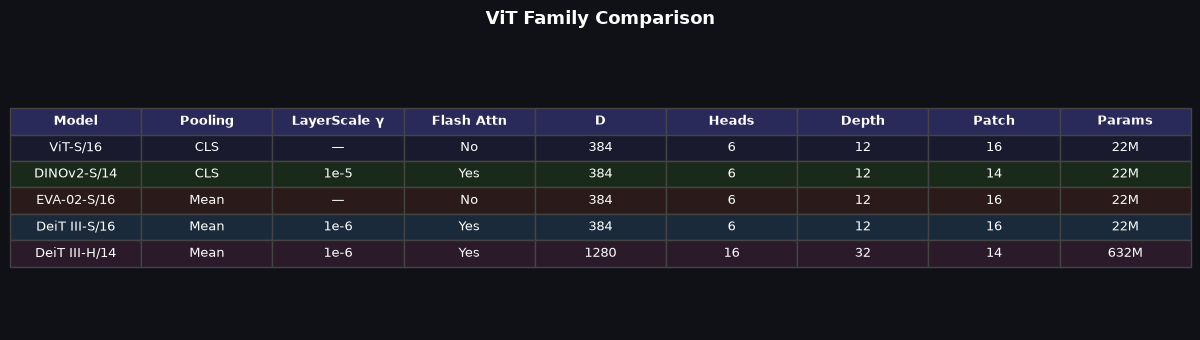

In [2]:
# ── Side-by-side model summary table ────────────────────────────────────────
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 3.5))
fig.patch.set_facecolor('#0f1117')
ax.set_facecolor('#0f1117')
ax.axis('off')

columns = ['Model', 'Pooling', 'LayerScale γ', 'Flash Attn', 'D', 'Heads', 'Depth', 'Patch', 'Params']
rows = [
    ['ViT-S/16',       'CLS',      '—',     'No',  '384',  '6',  '12', '16', '22M'],
    ['DINOv2-S/14',    'CLS',      '1e-5',  'Yes', '384',  '6',  '12', '14', '22M'],
    ['EVA-02-S/16',    'Mean',     '—',     'No',  '384',  '6',  '12', '16', '22M'],
    ['DeiT III-S/16',  'Mean',     '1e-6',  'Yes', '384',  '6',  '12', '16', '22M'],
    ['DeiT III-H/14',  'Mean',     '1e-6',  'Yes', '1280', '16', '32', '14', '632M'],
]
row_colors = ['#1a1a2e', '#1a2a1a', '#2a1a1a', '#1a2a3a', '#2a1a2a']

table = ax.table(
    cellText=rows,
    colLabels=columns,
    cellLoc='center',
    loc='center'
)
table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1.2, 1.5)

for (row, col), cell in table.get_celld().items():
    if row == 0:
        cell.set_facecolor('#2a2a5a')
        cell.set_text_props(color='white', fontweight='bold')
    else:
        cell.set_facecolor(row_colors[row - 1])
        cell.set_text_props(color='white')
    cell.set_edgecolor('#444')

ax.set_title('ViT Family Comparison', color='white', fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()

plt.show()

## 3. Key ideas

## Key Innovations

### 1. LayerScale — γ Initialised at 1e-6 (Smaller than DINOv2)

LayerScale was introduced in CaiT (Touvron et al., 2021). DeiT III reuses it with a **smaller initial value** than DINOv2 (1e-6 vs 1e-5):

$$x \leftarrow x + \underbrace{\gamma_1}_{\in \mathbb{R}^D,\ \gamma \approx 10^{-6}} \odot \text{Attention}(\text{LN}(x))$$

**Why 1e-6 instead of 1e-5?** The 3-Augmentation training recipe creates larger gradient perturbations at the start of training (strong augmentations produce high-variance gradients). A smaller $\gamma$ provides a stronger early constraint, preventing the network from learning harmful patterns in the first few epochs.

At convergence, $\gamma$ may approach 1.0 (full residual) or remain small — the network decides based on the task.

### 2. No CLS Token — Symmetric Mean Pooling

ViT's CLS token creates an **asymmetry**: the CLS token can attend to all patches, but patches are also modified by the CLS token's presence. This means:
- CLS token learns a role different from patch tokens
- Patch tokens encode both local features **and** global context signals (some dimensions are used to signal CLS)

DeiT III removes this asymmetry with mean pooling:
$$z = \frac{1}{N} \sum_{i=1}^{N} \text{LN}(x)_i$$

Benefits:
- All patch tokens are trained equally
- Each patch token is a good local descriptor without needing to encode global summary info
- Simpler: one fewer learnable token
- Better for dense prediction (no CLS takes up attention head capacity)

### 3. The Key Claim: Recipe > Architecture

The paper's core argument is that **the training recipe matters more than architectural complexity**. DeiT III shows:
- Plain ViT-L trained with 3-Augmentation + good hyperparameters
- Achieves **86.5% top-1 on ImageNet-1K** without extra data or self-supervised pre-training
- Outperforms many complex self-supervised methods when fine-tuned

3-Augmentation components (not in backbone code — applied in training pipeline):
1. RandomResizedCrop + horizontal flip
2. RandAugment (n=2, m=9)
3. Random Erasing (p=0.25)
4. Mixup (α=0.8) + CutMix (α=1.0)
5. Label smoothing (ε=0.1) + Repeated augmentation

### 4. Variants
| Name | D | Heads | Layers | Patch | Params |
|------|---|-------|--------|-------|--------|
| DeiT III-S/16 | 384 | 6 | 12 | 16 | ~22M |
| DeiT III-B/16 | 768 | 12 | 12 | 16 | ~86M |
| DeiT III-L/16 | 1024 | 16 | 24 | 16 | ~307M |
| DeiT III-H/14 | 1280 | 16 | 32 | 14 | ~632M |

## Module Walkthrough

### DeiT3Block — Full Block with LayerScale
```python
class DeiT3Block(nn.Module):
    def __init__(self, dim, num_heads, ls_init=1e-6):
        self.norm1 = nn.LayerNorm(dim)
        self.attn  = DeiT3Attention(dim, num_heads)  # Flash Attention
        self.ls1   = LayerScale(dim, init_value=ls_init)  # γ = 1e-6 * ones(D)
        self.norm2 = nn.LayerNorm(dim)
        self.mlp   = ViTMLP(dim, mlp_ratio=4.0)
        self.ls2   = LayerScale(dim, init_value=ls_init)

    def forward(self, x):
        attn_out, _ = self.attn(self.norm1(x))
        x = x + self.ls1(attn_out)              # scaled residual branch 1
        x = x + self.ls2(self.mlp(self.norm2(x)))  # scaled residual branch 2
        return x
```

### DeiT3Backbone — Forward Pass
```python
def forward(self, x):       # x: [B, 3, H, W]
    x = self.patch_embed(x)              # [B, N, D]
    x = self.pos_drop(x + self.pos_embed)  # add absolute pos embedding
    # No CLS token prepended — all N patches treated equally
    for blk in self.blocks:
        x, _ = blk(x)
    x = self.norm(x)                     # [B, N, D]
    pooled = x.mean(dim=1)               # [B, D] — mean pool over patches
    # Compare: ViT uses x[:, 0] (CLS token)
    feat_map = x.T(1,2).reshape(B, D, G, G)
    return BackboneOutput(pooled, x, [feat_map])
```

### LayerScale — Reused from DINOv2
```python
class LayerScale(nn.Module):
    def __init__(self, dim, init_value=1e-6):  # DeiT III uses 1e-6
        self.gamma = nn.Parameter(init_value * torch.ones(dim))
    def forward(self, x):
        return x * self.gamma   # [B, N, D] * [D] → broadcast over B, N
```

## 4. The architecture in pure PyTorch

Below is the **complete implementation** used by HaleBlocks (`hale_core/nn/vision/vit/deit3.py`), one top-level
definition per cell, with its original comments and docstrings. Only the `hale_core` imports were replaced by the
two foundation cells (the `BackboneOutput` / `BaseVisionBackbone` contract and a 10-line registry), so this notebook
runs anywhere PyTorch is installed. §7 checks it is bit-for-bit the library implementation.

<details><summary>Module docstring of <code>vit/deit3.py</code></summary>

```text
DeiT III Vision Transformer Backbone
======================================

Paper: "DeiT III: Revenge of the ViT" (Touvron et al., 2022)
       https://arxiv.org/abs/2204.07118

Architecture Overview
---------------------
DeiT III demonstrates that a vanilla ViT trained with the right data augmentation
and regularisation recipe (3-Augmentation, or 3-Reg) matches or beats more complex
architectures.  The architectural changes over baseline ViT are minimal:

1. LayerScale (Touvron et al., 2021 — CaiT)
   Same as DINOv2: per-channel learnable scale γ on each residual branch.
   Initial value: 1e-6 for large models (smaller than DINOv2's 1e-5 to handle
   more aggressive augmentation at the start of training).
   γ is a free parameter — at convergence it may be near 1.0 (full residual)
   or remain small (dampened contribution).

2. No CLS token — mean-pooling
   Unlike baseline ViT which uses a CLS token, DeiT III pools all patch tokens:
       pooled = mean(patch_tokens, dim=1)
   This removes the asymmetry between CLS and patch tokens, and all patches
   contribute equally to the global representation.  This simplifies transfer
   learning: any patch can be used for dense prediction without the CLS token
   occupying a "special" position.

3. Absolute learned positional embeddings (same as ViT)
   DeiT III does NOT use RoPE — it keeps the simple learned absolute embeddings.
   The 3-Reg augmentation (Random Resize Crop, RandAugment, Random Erasing) is
   the key to the strong performance, not architecture changes.

3-Augmentation training recipe (not implemented here, documented for reference)
  - RandomResizedCrop(224)
  - RandAugment(n=2, m=9) — two magnitude-9 transformations per image
  - RandomErasing(prob=0.25, scale=(0.02, 0.33))
  - Mixup(alpha=0.8) + CutMix(alpha=1.0)
  - Label smoothing (ε=0.1)
  - Repeated augmentation (same image augmented twice per batch for diversity)
  This recipe is applied in the training pipeline, not the backbone.

Variants registered
-------------------
  deit3_small — 384-dim, 6 heads,  12 layers, patch=16
  deit3_base  — 768-dim, 12 heads, 12 layers, patch=16
  deit3_large — 1024-dim, 16 heads, 24 layers, patch=16
  deit3_huge  — 1280-dim, 16 heads, 32 layers, patch=14
```
</details>

In [3]:
from __future__ import annotations

# Everything below is plain PyTorch - no hale_core import is needed to run this notebook.
import math
from abc import ABC, abstractmethod
from copy import deepcopy
from dataclasses import dataclass, field
from typing import Any, Callable, Optional, Type, TypeVar, Union

import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
torch.set_num_threads(min(4, torch.get_num_threads()))
print("torch", torch.__version__)

torch 2.14.1


### 4.1 Foundation: the backbone contract (`base.py`) and a local registry

In [4]:
@dataclass
class BackboneOutput:
    """Standard output container for all vision backbones.

    Attributes
    ----------
    pooled_output:
        Global image representation after spatial pooling. Shape [B, embed_dim].
        Used by: classification heads, VLM projectors, action encoders.

    patch_tokens:
        Per-patch (or per-pixel) feature tokens BEFORE pooling.
        Shape [B, N, embed_dim] for ViT-style; None for pure CNNs.
        Used by: VLM cross-attention, dense grounding.

    feature_maps:
        Multi-scale spatial feature tensors, ordered finest → coarsest.
        Each element: [B, C_i, H/s_i, W/s_i] where s_i is the stride.
        Used by: FPN, BEV encoder, depth heads.

    attentions:
        Optional list of attention weight tensors from each transformer block.
        Used for interpretability (attention rollout, DINO self-supervised heads).
    """

    pooled_output: torch.Tensor                          # [B, embed_dim]
    patch_tokens:  Optional[torch.Tensor] = None        # [B, N, D] or None
    feature_maps:  list[torch.Tensor] = field(default_factory=list)  # multi-scale
    attentions:    Optional[list[torch.Tensor]] = None  # transformer attention maps


class BaseVisionBackbone(ABC, nn.Module):
    """Abstract base for all vision backbones.

    Subclasses MUST define:
      - arch_name  (str): human-readable identifier, e.g. "resnet50"
      - embed_dim  (int): dimension of pooled_output
      - feature_dims (list[int]): channel counts for each feature map scale
      - forward(x) -> BackboneOutput

    Args:
        img_size:   Expected input spatial resolution (height == width assumed).
        in_chans:   Number of input image channels (default 3 for RGB).
        drop_rate:  Dropout probability applied to the final pooled features.
        out_indices: Which multi-scale feature stages to include in BackboneOutput.
                     E.g. [0, 1, 2, 3] returns all four scales; [2, 3] returns
                     only the two coarsest.  Default returns all available.
    """

    # ── Class-level metadata — override in each subclass ─────────────────────
    arch_name:    str        = "base"
    embed_dim:    int        = 0
    feature_dims: list[int] = []   # channel counts per stage, finest→coarsest

    def __init__(
        self,
        img_size:    int        = 224,
        in_chans:    int        = 3,
        drop_rate:   float      = 0.0,
        out_indices: list[int] | None = None,
    ) -> None:
        super().__init__()
        self.img_size    = img_size
        self.in_chans    = in_chans
        self.drop_rate   = drop_rate
        self.out_indices = out_indices  # None = return all stages

    @abstractmethod
    def forward(self, x: torch.Tensor) -> BackboneOutput:
        """Run the backbone on a batch of images.

        Args:
            x: Float32 tensor of shape [B, in_chans, H, W].
               Typically ImageNet-normalised (mean=[0.485,0.456,0.406],
               std=[0.229,0.224,0.225]).

        Returns:
            BackboneOutput with pooled_output, patch_tokens, feature_maps.
        """
        ...

    # ── Convenience helpers ───────────────────────────────────────────────────

    def num_parameters(self, trainable_only: bool = False) -> int:
        """Count model parameters.

        Args:
            trainable_only: If True, count only parameters with requires_grad=True.

        Returns:
            Integer parameter count.
        """
        params = self.parameters()
        if trainable_only:
            params = (p for p in params if p.requires_grad)
        return sum(p.numel() for p in params)

    def freeze_all(self) -> None:
        """Freeze all parameters (no gradient computation).

        Useful when using the backbone as a frozen feature extractor
        inside a VLM or action decoder that only trains the head.
        """
        for p in self.parameters():
            p.requires_grad_(False)

    def unfreeze_all(self) -> None:
        """Unfreeze all parameters."""
        for p in self.parameters():
            p.requires_grad_(True)

    def freeze_up_to_stage(self, stage: int) -> None:
        """Freeze all stages from 0 up to and including `stage`.

        Useful for fine-tuning: freeze the early feature extractor stages
        and only fine-tune the later stages.  The exact meaning of "stage"
        is backbone-specific; see each subclass's docstring.

        Args:
            stage: Stage index (0-based).  Stages 0..stage are frozen.
        """
        raise NotImplementedError(
            f"{self.__class__.__name__} does not implement freeze_up_to_stage()"
        )

    def __repr__(self) -> str:
        return (
            f"{self.__class__.__name__}("
            f"arch={self.arch_name}, "
            f"embed_dim={self.embed_dim}, "
            f"img_size={self.img_size}, "
            f"params={self.num_parameters():,})"
        )

In [5]:
# A minimal stand-in for hale_core.nn.vision.registry: same decorator name and behaviour, so the
# library source below runs unchanged. Re-registration is allowed so cells can be re-run.
_VISION_BACKBONES: dict[str, type] = {}
T = TypeVar("T")


def register_vision_backbone(name: str) -> Callable[[T], T]:
    """Class decorator: store ``cls`` under ``name`` (lower-case)."""
    def decorator(cls: T) -> T:
        _VISION_BACKBONES[name.lower()] = cls
        return cls
    return decorator


def build_vision_backbone(name: str, **kwargs: Any) -> "BaseVisionBackbone":
    """Instantiate a backbone registered in this notebook."""
    return _VISION_BACKBONES[name.lower()](**kwargs)


def list_vision_backbones() -> list[str]:
    return sorted(_VISION_BACKBONES)

### Shared building blocks from `vit/vit.py` used by this family: `PatchEmbed`, `ViTMLP`, `_trunc_normal_`, `ViTSmall`

In [6]:
def _trunc_normal_(tensor: torch.Tensor, std: float = 0.02) -> torch.Tensor:
    """Truncated normal init at ±2σ — standard for ViT weight init."""
    with torch.no_grad():
        # Box–Muller via normal + clamp, then rescale to correct distribution
        nn.init.trunc_normal_(tensor, mean=0.0, std=std, a=-2 * std, b=2 * std)
    return tensor


class PatchEmbed(nn.Module):
    """Convert an image into non-overlapping patch embeddings.

    Uses a single Conv2d with kernel_size=stride=patch_size, which is
    mathematically equivalent to splitting the image into patches and applying
    a shared linear projection to each, but is faster due to BLAS layout.

    Args:
        img_size:   Assumed square input size (used to pre-compute N_patches).
        patch_size: Side length of each square patch (e.g. 16 or 14).
        in_chans:   Input channels (3 for RGB).
        embed_dim:  Projected dimension D.
    """

    def __init__(
        self,
        img_size: int = 224,
        patch_size: int = 16,
        in_chans: int = 3,
        embed_dim: int = 768,
    ) -> None:
        super().__init__()
        self.img_size = img_size
        self.patch_size = patch_size
        self.grid_size = img_size // patch_size          # e.g. 14 for 224/16
        self.num_patches = self.grid_size ** 2

        # A single strided convolution performs the patch extraction + linear projection
        self.proj = nn.Conv2d(in_chans, embed_dim, kernel_size=patch_size, stride=patch_size)
        _trunc_normal_(self.proj.weight)
        nn.init.zeros_(self.proj.bias)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # x: [B, C, H, W] → [B, D, H/p, W/p] → [B, N, D]
        x = self.proj(x)                                 # [B, D, G, G]
        x = x.flatten(2).transpose(1, 2)                # [B, N, D]
        return x


class ViTAttention(nn.Module):
    """Multi-head self-attention for Vision Transformer.

    Implements the standard scaled dot-product attention:
        Attn(Q,K,V) = softmax(QK^T / √d_head) · V

    Uses a single in_proj weight matrix [D, 3D] for combined Q/K/V — this is
    cache-friendly and matches the original Transformer paper's formulation.

    Args:
        dim:       Input/output dimensionality D.
        num_heads: Number of attention heads H. dim must be divisible by H.
        attn_drop: Dropout probability on attention weights (default 0.0).
        proj_drop: Dropout probability on the output projection (default 0.0).
    """

    def __init__(
        self,
        dim: int,
        num_heads: int = 8,
        attn_drop: float = 0.0,
        proj_drop: float = 0.0,
    ) -> None:
        super().__init__()
        assert dim % num_heads == 0, f"dim {dim} must be divisible by num_heads {num_heads}"
        self.num_heads = num_heads
        self.head_dim = dim // num_heads
        self.scale = self.head_dim ** -0.5               # 1/√d_head for numerical stability

        # Combined Q, K, V projection — one matrix instead of three for efficiency
        self.in_proj = nn.Linear(dim, dim * 3, bias=True)
        self.out_proj = nn.Linear(dim, dim, bias=True)
        self.attn_drop = nn.Dropout(attn_drop)
        self.proj_drop = nn.Dropout(proj_drop)

        _trunc_normal_(self.in_proj.weight)
        _trunc_normal_(self.out_proj.weight)
        nn.init.zeros_(self.in_proj.bias)
        nn.init.zeros_(self.out_proj.bias)

    def forward(
        self, x: torch.Tensor, return_attn: bool = False
    ) -> tuple[torch.Tensor, Optional[torch.Tensor]]:
        B, N, D = x.shape
        H = self.num_heads

        # Project and split into Q, K, V heads
        qkv = self.in_proj(x)                            # [B, N, 3D]
        qkv = qkv.reshape(B, N, 3, H, self.head_dim)    # [B, N, 3, H, d]
        qkv = qkv.permute(2, 0, 3, 1, 4)                # [3, B, H, N, d]
        q, k, v = qkv.unbind(0)                          # each [B, H, N, d]

        # Scaled dot-product attention
        attn = (q @ k.transpose(-2, -1)) * self.scale    # [B, H, N, N]
        attn = F.softmax(attn, dim=-1)
        attn = self.attn_drop(attn)

        # Weighted sum of values
        x = (attn @ v).transpose(1, 2).reshape(B, N, D)  # [B, N, D]
        x = self.proj_drop(self.out_proj(x))

        return x, (attn if return_attn else None)


class ViTMLP(nn.Module):
    """Two-layer GELU MLP, expand ratio 4× (standard ViT FFN).

    Structure: Linear(D → 4D) → GELU → Dropout → Linear(4D → D) → Dropout
    """

    def __init__(self, dim: int, mlp_ratio: float = 4.0, drop: float = 0.0) -> None:
        super().__init__()
        hidden = int(dim * mlp_ratio)
        self.fc1 = nn.Linear(dim, hidden)
        self.act = nn.GELU()
        self.drop1 = nn.Dropout(drop)
        self.fc2 = nn.Linear(hidden, dim)
        self.drop2 = nn.Dropout(drop)

        _trunc_normal_(self.fc1.weight)
        _trunc_normal_(self.fc2.weight)
        nn.init.zeros_(self.fc1.bias)
        nn.init.zeros_(self.fc2.bias)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.drop1(self.act(self.fc1(x)))
        return self.drop2(self.fc2(x))


class ViTBlock(nn.Module):
    """Single ViT encoder block: pre-norm → attention → pre-norm → MLP.

    Pre-norm (LN before the residual branch) is more stable than post-norm,
    especially for large models and long sequences.

    Residual formulation:
        x = x + Attention(LayerNorm(x))
        x = x + MLP(LayerNorm(x))
    """

    def __init__(
        self,
        dim: int,
        num_heads: int,
        mlp_ratio: float = 4.0,
        attn_drop: float = 0.0,
        mlp_drop: float = 0.0,
    ) -> None:
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attn = ViTAttention(dim, num_heads=num_heads, attn_drop=attn_drop, proj_drop=mlp_drop)
        self.norm2 = nn.LayerNorm(dim)
        self.mlp = ViTMLP(dim, mlp_ratio=mlp_ratio, drop=mlp_drop)

    def forward(
        self, x: torch.Tensor, return_attn: bool = False
    ) -> tuple[torch.Tensor, Optional[torch.Tensor]]:
        attn_out, attn_weights = self.attn(self.norm1(x), return_attn=return_attn)
        x = x + attn_out
        x = x + self.mlp(self.norm2(x))
        return x, attn_weights


class ViTBackbone(BaseVisionBackbone):
    """Standard Vision Transformer backbone.

    Returns a BackboneOutput where:
      - pooled_output:  CLS token embedding [B, embed_dim]
      - patch_tokens:   All patch token embeddings [B, N, embed_dim]
      - feature_maps:   Patch tokens reshaped to spatial grid [B, D, H/p, W/p]
                        Single-scale (ViT has no multi-scale FPN hierarchy)

    Args:
        embed_dim:    Token dimension D.
        depth:        Number of transformer blocks.
        num_heads:    Attention heads per block.
        patch_size:   Side length of each patch (16 or 14).
        mlp_ratio:    FFN hidden dim multiplier (default 4.0).
        attn_drop:    Dropout on attention weights.
        drop_rate:    Dropout on patch embeddings and MLP outputs.
        return_all_attn: If True, cache attention maps from all blocks.
        img_size, in_chans, out_indices: inherited from BaseVisionBackbone.
    """

    arch_name: str = "vit"

    def __init__(
        self,
        img_size: int = 224,
        in_chans: int = 3,
        embed_dim: int = 768,
        depth: int = 12,
        num_heads: int = 12,
        patch_size: int = 16,
        mlp_ratio: float = 4.0,
        attn_drop: float = 0.0,
        drop_rate: float = 0.0,
        return_all_attn: bool = False,
        out_indices: list[int] | None = None,
    ) -> None:
        super().__init__(img_size=img_size, in_chans=in_chans, drop_rate=drop_rate, out_indices=out_indices)
        self.embed_dim = embed_dim
        self.patch_size = patch_size
        self.depth = depth
        self.return_all_attn = return_all_attn
        self.feature_dims = [embed_dim]  # single-scale ViT

        # Patch projection
        self.patch_embed = PatchEmbed(img_size, patch_size, in_chans, embed_dim)
        num_patches = self.patch_embed.num_patches

        # CLS token and positional embeddings
        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, num_patches + 1, embed_dim))
        self.pos_drop = nn.Dropout(drop_rate)

        # Transformer blocks
        self.blocks = nn.ModuleList([
            ViTBlock(embed_dim, num_heads, mlp_ratio=mlp_ratio, attn_drop=attn_drop, mlp_drop=drop_rate)
            for _ in range(depth)
        ])

        self.norm = nn.LayerNorm(embed_dim)

        self._init_weights()

    def _init_weights(self) -> None:
        _trunc_normal_(self.cls_token)
        _trunc_normal_(self.pos_embed)

    def freeze_up_to_stage(self, stage: int) -> None:
        """Freeze the first `stage` transformer blocks (0-indexed).

        Stage mapping:
          stage=0 → freeze patch_embed, cls_token, pos_embed, blocks[0]
          stage=k → additionally freeze blocks[1..k]
        """
        # Freeze embeddings
        self.patch_embed.requires_grad_(False)
        self.cls_token.requires_grad_(False)
        self.pos_embed.requires_grad_(False)
        # Freeze first (stage+1) blocks
        for i in range(min(stage + 1, self.depth)):
            self.blocks[i].requires_grad_(False)

    def forward(self, x: torch.Tensor) -> BackboneOutput:
        B = x.shape[0]

        # 1. Patch embedding
        x = self.patch_embed(x)                          # [B, N, D]

        # 2. Prepend CLS token and add positional embedding
        cls = self.cls_token.expand(B, -1, -1)           # [B, 1, D]
        x = torch.cat([cls, x], dim=1)                   # [B, N+1, D]
        x = self.pos_drop(x + self.pos_embed)

        # 3. Transformer blocks
        attn_maps: list[torch.Tensor] = []
        for blk in self.blocks:
            x, attn = blk(x, return_attn=self.return_all_attn)
            if self.return_all_attn and attn is not None:
                attn_maps.append(attn)

        x = self.norm(x)                                  # [B, N+1, D]

        # 4. Unpack outputs
        pooled = x[:, 0]                                  # [B, D]  — CLS token
        patches = x[:, 1:]                                # [B, N, D]

        # Reshape to spatial grid for dense tasks
        G = self.patch_embed.grid_size
        feat_map = patches.transpose(1, 2).reshape(B, self.embed_dim, G, G)  # [B, D, G, G]

        return BackboneOutput(
            pooled_output=pooled,
            patch_tokens=patches,
            feature_maps=[feat_map],
            attentions=attn_maps if self.return_all_attn else None,
        )


@register_vision_backbone("vit_small")
class ViTSmall(ViTBackbone):
    """ViT-S/16 — 22M params. Good accuracy/speed trade-off."""
    arch_name = "vit_small"
    feature_dims = [384]

    def __init__(self, **kwargs) -> None:
        kwargs.setdefault("embed_dim", 384)
        kwargs.setdefault("depth", 12)
        kwargs.setdefault("num_heads", 6)
        kwargs.setdefault("patch_size", 16)
        super().__init__(**kwargs)

### Shared building blocks from `vit/dino.py` used by this family: `LayerScale`

In [7]:
class LayerScale(nn.Module):
    """Per-channel learned scale applied to a residual branch.

    Initialised at `init_value` (≈1e-5 for large models) so residuals start
    near zero.  The scale is learned and grows during training, allowing the
    network to gradually increase the residual contribution.

    Reference: "Going Deeper with Image Transformers" (Touvron et al., 2021)
               https://arxiv.org/abs/2103.17239
    """

    def __init__(self, dim: int, init_value: float = 1e-5) -> None:
        super().__init__()
        # Scalar per output channel; starts small to dampen residuals initially
        self.gamma = nn.Parameter(init_value * torch.ones(dim))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return x * self.gamma

### 4.2 `vit/deit3.py`, definition by definition

**`DeiT3Attention`** - Standard multi-head self-attention for DeiT III.

In [8]:
class DeiT3Attention(nn.Module):
    """Standard multi-head self-attention for DeiT III.

    Uses PyTorch 2.0 fused kernel (F.scaled_dot_product_attention) when available.
    No register tokens, no LayerScale inside the attention — LayerScale is on the block.
    """

    def __init__(
        self,
        dim: int,
        num_heads: int = 8,
        attn_drop: float = 0.0,
        proj_drop: float = 0.0,
    ) -> None:
        super().__init__()
        assert dim % num_heads == 0
        self.num_heads = num_heads
        self.head_dim = dim // num_heads
        self.scale = self.head_dim ** -0.5
        self.attn_drop_p = attn_drop
        self._use_flash = hasattr(F, "scaled_dot_product_attention")

        self.in_proj = nn.Linear(dim, dim * 3, bias=True)
        self.out_proj = nn.Linear(dim, dim, bias=True)
        self.proj_drop = nn.Dropout(proj_drop)

        _trunc_normal_(self.in_proj.weight)
        _trunc_normal_(self.out_proj.weight)
        nn.init.zeros_(self.in_proj.bias)
        nn.init.zeros_(self.out_proj.bias)

    def forward(
        self, x: torch.Tensor, return_attn: bool = False
    ) -> tuple[torch.Tensor, Optional[torch.Tensor]]:
        B, N, D = x.shape
        H = self.num_heads

        qkv = self.in_proj(x).reshape(B, N, 3, H, self.head_dim).permute(2, 0, 3, 1, 4)
        q, k, v = qkv.unbind(0)

        if self._use_flash and not return_attn:
            drop_p = self.attn_drop_p if self.training else 0.0
            x = F.scaled_dot_product_attention(q, k, v, dropout_p=drop_p)
            attn_weights = None
        else:
            attn = (q @ k.transpose(-2, -1)) * self.scale
            attn = F.softmax(attn, dim=-1)
            if self.training and self.attn_drop_p > 0:
                attn = F.dropout(attn, p=self.attn_drop_p)
            attn_weights = attn if return_attn else None
            x = attn @ v

        x = x.transpose(1, 2).reshape(B, N, D)
        return self.proj_drop(self.out_proj(x)), attn_weights

**`DeiT3Block`** - DeiT III transformer block: pre-norm + LayerScale, GELU MLP.

In [9]:
class DeiT3Block(nn.Module):
    """DeiT III transformer block: pre-norm + LayerScale, GELU MLP.

    Key: LayerScale init is 1e-6 (smaller than DINOv2's 1e-5) to accommodate
    the more aggressive 3-Augmentation training recipe that perturbs gradients
    more strongly at the start.

    Residual:
        x = x + LayerScale_attn(Attention(LN(x)))
        x = x + LayerScale_mlp(MLP(LN(x)))
    """

    def __init__(
        self,
        dim: int,
        num_heads: int,
        mlp_ratio: float = 4.0,
        attn_drop: float = 0.0,
        mlp_drop: float = 0.0,
        ls_init: float = 1e-6,
    ) -> None:
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attn = DeiT3Attention(dim, num_heads=num_heads, attn_drop=attn_drop, proj_drop=mlp_drop)
        self.ls1 = LayerScale(dim, init_value=ls_init)

        self.norm2 = nn.LayerNorm(dim)
        self.mlp = ViTMLP(dim, mlp_ratio=mlp_ratio, drop=mlp_drop)
        self.ls2 = LayerScale(dim, init_value=ls_init)

    def forward(
        self, x: torch.Tensor, return_attn: bool = False
    ) -> tuple[torch.Tensor, Optional[torch.Tensor]]:
        attn_out, attn_weights = self.attn(self.norm1(x), return_attn=return_attn)
        x = x + self.ls1(attn_out)
        x = x + self.ls2(self.mlp(self.norm2(x)))
        return x, attn_weights

**`DeiT3Backbone`** - DeiT III backbone: ViT with LayerScale and mean-pool (no CLS token).

In [10]:
class DeiT3Backbone(BaseVisionBackbone):
    """DeiT III backbone: ViT with LayerScale and mean-pool (no CLS token).

    Output:
      - pooled_output:  mean(patch_tokens, dim=1) [B, D]
      - patch_tokens:   all patch tokens [B, N, D]
      - feature_maps:   patch tokens as spatial grid [B, D, H/p, W/p]

    Args:
        embed_dim:     Token dimension D.
        depth:         Number of transformer blocks.
        num_heads:     Attention heads per block.
        patch_size:    Patch side length.
        ls_init:       LayerScale initial value (default 1e-6).
        mlp_ratio:     FFN expansion ratio (default 4.0).
        return_all_attn: Cache attention maps from all blocks.
    """

    arch_name: str = "deit3"

    def __init__(
        self,
        img_size: int = 224,
        in_chans: int = 3,
        embed_dim: int = 768,
        depth: int = 12,
        num_heads: int = 12,
        patch_size: int = 16,
        ls_init: float = 1e-6,
        mlp_ratio: float = 4.0,
        attn_drop: float = 0.0,
        drop_rate: float = 0.0,
        return_all_attn: bool = False,
        out_indices: list[int] | None = None,
    ) -> None:
        super().__init__(img_size=img_size, in_chans=in_chans, drop_rate=drop_rate, out_indices=out_indices)
        self.embed_dim = embed_dim
        self.patch_size = patch_size
        self.depth = depth
        self.return_all_attn = return_all_attn
        self.feature_dims = [embed_dim]

        self.patch_embed = PatchEmbed(img_size, patch_size, in_chans, embed_dim)
        num_patches = self.patch_embed.num_patches

        # Absolute learned positional embedding (no CLS token, so just N patches)
        self.pos_embed = nn.Parameter(torch.zeros(1, num_patches, embed_dim))
        self.pos_drop = nn.Dropout(drop_rate)

        self.blocks = nn.ModuleList([
            DeiT3Block(embed_dim, num_heads, mlp_ratio=mlp_ratio, attn_drop=attn_drop, mlp_drop=drop_rate, ls_init=ls_init)
            for _ in range(depth)
        ])

        self.norm = nn.LayerNorm(embed_dim)

        _trunc_normal_(self.pos_embed)

    def freeze_up_to_stage(self, stage: int) -> None:
        """Freeze patch embed, pos embed, and the first `stage` blocks."""
        self.patch_embed.requires_grad_(False)
        self.pos_embed.requires_grad_(False)
        for i in range(min(stage + 1, self.depth)):
            self.blocks[i].requires_grad_(False)

    def forward(self, x: torch.Tensor) -> BackboneOutput:
        B = x.shape[0]

        # 1. Patch embedding + positional encoding
        x = self.patch_embed(x)                         # [B, N, D]
        x = self.pos_drop(x + self.pos_embed)

        # 2. Transformer blocks
        attn_maps: list[torch.Tensor] = []
        for blk in self.blocks:
            x, attn = blk(x, return_attn=self.return_all_attn)
            if self.return_all_attn and attn is not None:
                attn_maps.append(attn)

        x = self.norm(x)                                # [B, N, D]

        # 3. Mean pooling over all patches (no special CLS token)
        pooled = x.mean(dim=1)                          # [B, D]

        # Spatial reshape for dense prediction heads
        G = self.patch_embed.grid_size
        feat_map = x.transpose(1, 2).reshape(B, self.embed_dim, G, G)  # [B, D, G, G]

        return BackboneOutput(
            pooled_output=pooled,
            patch_tokens=x,
            feature_maps=[feat_map],
            attentions=attn_maps if self.return_all_attn else None,
        )

**`DeiT3Small`** - DeiT III-S/16 — 22M params.

In [11]:
@register_vision_backbone("deit3_small")
class DeiT3Small(DeiT3Backbone):
    """DeiT III-S/16 — 22M params."""
    arch_name = "deit3_small"
    feature_dims = [384]

    def __init__(self, **kwargs) -> None:
        kwargs.setdefault("embed_dim", 384)
        kwargs.setdefault("depth", 12)
        kwargs.setdefault("num_heads", 6)
        kwargs.setdefault("patch_size", 16)
        kwargs.setdefault("ls_init", 1e-6)
        super().__init__(**kwargs)

**`DeiT3Base`** - DeiT III-B/16 — 86M params.

In [12]:
@register_vision_backbone("deit3_base")
class DeiT3Base(DeiT3Backbone):
    """DeiT III-B/16 — 86M params."""
    arch_name = "deit3_base"
    feature_dims = [768]

    def __init__(self, **kwargs) -> None:
        kwargs.setdefault("embed_dim", 768)
        kwargs.setdefault("depth", 12)
        kwargs.setdefault("num_heads", 12)
        kwargs.setdefault("patch_size", 16)
        kwargs.setdefault("ls_init", 1e-6)
        super().__init__(**kwargs)

**`DeiT3Large`** - DeiT III-L/16 — 307M params.

In [13]:
@register_vision_backbone("deit3_large")
class DeiT3Large(DeiT3Backbone):
    """DeiT III-L/16 — 307M params."""
    arch_name = "deit3_large"
    feature_dims = [1024]

    def __init__(self, **kwargs) -> None:
        kwargs.setdefault("embed_dim", 1024)
        kwargs.setdefault("depth", 24)
        kwargs.setdefault("num_heads", 16)
        kwargs.setdefault("patch_size", 16)
        kwargs.setdefault("ls_init", 1e-6)
        super().__init__(**kwargs)

**`DeiT3Huge`** - DeiT III-H/14 — 632M params.  The flagship DeiT III model.

In [14]:
@register_vision_backbone("deit3_huge")
class DeiT3Huge(DeiT3Backbone):
    """DeiT III-H/14 — 632M params.  The flagship DeiT III model."""
    arch_name = "deit3_huge"
    feature_dims = [1280]

    def __init__(self, **kwargs) -> None:
        kwargs.setdefault("embed_dim", 1280)
        kwargs.setdefault("depth", 32)
        kwargs.setdefault("num_heads", 16)
        kwargs.setdefault("patch_size", 14)
        kwargs.setdefault("ls_init", 1e-6)
        super().__init__(**kwargs)

## 5. Build and run it

Every variant defined above is now in the notebook's registry. Build the demo variants, run a batch through them and
check the `BackboneOutput` contract: `pooled_output (B, embed_dim)`, multi-scale `feature_maps` (finest → coarsest)
and, for transformers, `patch_tokens`. The **stride** of each map is `input size / map size`.

In [15]:
DEMOS = {'deit3_small': 22.1}          # variant -> paper parameter count (M, incl. 1000-class head)
IMG = 224
print("variants defined in this notebook:", list_vision_backbones())

x = torch.randn(2, 3, IMG, IMG)
models = {}
for name in DEMOS:
    torch.manual_seed(0)
    model = build_vision_backbone(name, img_size=IMG).eval()
    models[name] = model
    with torch.no_grad():
        out = model(x)
    print(f"\n{name}  ({type(model).__name__})")
    print(f"  pooled_output : {tuple(out.pooled_output.shape)}   embed_dim = {model.embed_dim}")
    if out.patch_tokens is not None:
        print(f"  patch_tokens  : {tuple(out.patch_tokens.shape)}")
    for i, fm in enumerate(out.feature_maps):
        print(f"  feature_map {i}: {tuple(fm.shape)}   stride {IMG / fm.shape[-1]:.0f}")
    assert out.pooled_output.shape == (2, model.embed_dim)

variants defined in this notebook: ['deit3_base', 'deit3_huge', 'deit3_large', 'deit3_small', 'vit_small']



deit3_small  (DeiT3Small)
  pooled_output : (2, 384)   embed_dim = 384
  patch_tokens  : (2, 196, 384)
  feature_map 0: (2, 384, 14, 14)   stride 16


## 6. Parameter count vs the paper

Papers report parameters *including* the 1000-class classifier; the backbone has none, so `+ head` adds
`embed_dim × 1000 + 1000`. ✅ = within 5 % of the paper.

In [16]:
print(f"{'variant':20s} {'backbone':>10s} {'+ head':>10s} {'paper':>8s} {'ratio':>7s}")
for name, paper in DEMOS.items():
    model = models[name]
    p = sum(t.numel() for t in model.parameters()) / 1e6
    with_head = p + (model.embed_dim * 1000 + 1000) / 1e6
    if paper is None:
        print(f"{name:20s} {p:9.2f}M {with_head:9.2f}M {'n/a':>8s}")
        continue
    ratio = with_head / paper
    print(f"{name:20s} {p:9.2f}M {with_head:9.2f}M {paper:7.1f}M {ratio:7.2f}  {'✅' if abs(ratio - 1) < 0.05 else '⚠️ differs from paper'}")

variant                backbone     + head    paper   ratio
deit3_small              21.67M     22.06M    22.1M    1.00  ✅


### Gradient flow

A backbone is only useful if every parameter is trained. Back-propagate a scalar through the pooled output **and**
all feature maps and list parameters that receive no gradient.

In [17]:
for name, model in models.items():
    model.train().zero_grad()
    out = model(torch.randn(2, 3, IMG, IMG))
    loss = out.pooled_output.square().mean() + sum(fm.square().mean() for fm in out.feature_maps)
    loss.backward()
    dead = [n for n, p in model.named_parameters() if p.requires_grad and (p.grad is None or not torch.isfinite(p.grad).all())]
    total = sum(1 for p in model.parameters() if p.requires_grad)
    print(f"{name}: loss {loss.item():.4f} | {total - len(dead)}/{total} parameter tensors receive a finite gradient")
    if dead:
        print("   no gradient:", dead[:8], "..." if len(dead) > 8 else "")
    model.eval()

deit3_small: loss 1.0052 | 173/173 parameter tensors receive a finite gradient


## 7. Same code as the library?

If `hale_core` (HaleBlocks) is installed, build the library model, copy this notebook's weights into it with
`strict=True` (same parameter names and shapes) and compare outputs. A difference of `0.0` proves the code above *is*
the library implementation. Without HaleBlocks installed the check is skipped - the notebook itself is unaffected.

In [18]:
try:
    import logging, importlib
    logging.disable(logging.CRITICAL)
    try:
        from loguru import logger as _lg; _lg.remove()
    except ImportError:
        pass
    from hale_core.nn.vision.registry import build_vision_backbone as build_library_backbone
except ImportError:
    build_library_backbone = None
    print("hale_core is not installed here - skipping the library equivalence check.")

if build_library_backbone is not None:
    for name, model in models.items():
        lib = build_library_backbone(name, img_size=IMG).eval()
        lib.load_state_dict(model.state_dict(), strict=True)
        with torch.no_grad():
            a, b = model(x), lib(x)
        diff = max([(a.pooled_output - b.pooled_output).abs().max().item()] +
                   [(fa - fb).abs().max().item() for fa, fb in zip(a.feature_maps, b.feature_maps)])
        print(f"{name}: notebook vs hale_core max |diff| = {diff:.1e}  {'✅ identical' if diff == 0 else ''}")

deit3_small: notebook vs hale_core max |diff| = 0.0e+00  ✅ identical


## 8. What the feature maps look like

A synthetic image (a few coloured shapes) through the first demo variant: the channel-mean activation of every
feature map. Early maps keep edges at high resolution, late maps are coarse and semantic.

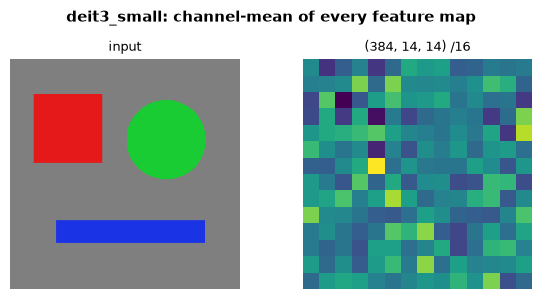

In [19]:
import matplotlib.pyplot as plt

def synthetic_image(size: int) -> torch.Tensor:
    """(1, 3, size, size) image with a red square, a green disc and a blue bar on grey."""
    yy, xx = torch.meshgrid(torch.linspace(0, 1, size), torch.linspace(0, 1, size), indexing="ij")
    img = torch.full((3, size, size), 0.5)
    sq = (xx > 0.1) & (xx < 0.4) & (yy > 0.15) & (yy < 0.45)
    disc = (xx - 0.68) ** 2 + (yy - 0.35) ** 2 < 0.03
    bar = (xx > 0.2) & (xx < 0.85) & (yy > 0.7) & (yy < 0.8)
    for mask, rgb in ((sq, (0.9, 0.1, 0.1)), (disc, (0.1, 0.8, 0.2)), (bar, (0.1, 0.2, 0.9))):
        for c in range(3):
            img[c][mask] = rgb[c]
    mean = torch.tensor([0.485, 0.456, 0.406])[:, None, None]
    std = torch.tensor([0.229, 0.224, 0.225])[:, None, None]
    return ((img - mean) / std)[None], img

name = next(iter(models))
inp, raw = synthetic_image(IMG)
with torch.no_grad():
    maps = models[name](inp).feature_maps
fig, axes = plt.subplots(1, len(maps) + 1, figsize=(3 * (len(maps) + 1), 3), facecolor="white")
axes[0].imshow(raw.permute(1, 2, 0)); axes[0].set_title("input", fontsize=9)
for ax, fm in zip(axes[1:], maps):
    ax.imshow(fm[0].mean(0), cmap="viridis")
    ax.set_title(f"{tuple(fm.shape[1:])} /{IMG // fm.shape[-1]}", fontsize=9)
for ax in axes:
    ax.axis("off")
plt.suptitle(f"{name}: channel-mean of every feature map", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

## 9. Experiments from the original walkthrough

The original notebook's hands-on cells, now running on the implementation defined in §4 (they used to import
`hale_core` through a relative `sys.path`, which only worked inside the HaleBlocks repo).

In [20]:
import sys
import numpy as np
import matplotlib.pyplot as plt

Parameters:  21,674,112
Embed dim:   384
Depth:       12

Block 0 - ls1 gamma[:5]: [1.e-06 1.e-06 1.e-06 1.e-06 1.e-06]
Block 0 - ls2 gamma[:5]: [1.e-06 1.e-06 1.e-06 1.e-06 1.e-06]
(All values = 1e-6 at init — near zero residuals)

pooled_output:  torch.Size([1, 384])
patch_tokens:   torch.Size([1, 196, 384])
feature_maps:   torch.Size([1, 384, 14, 14])


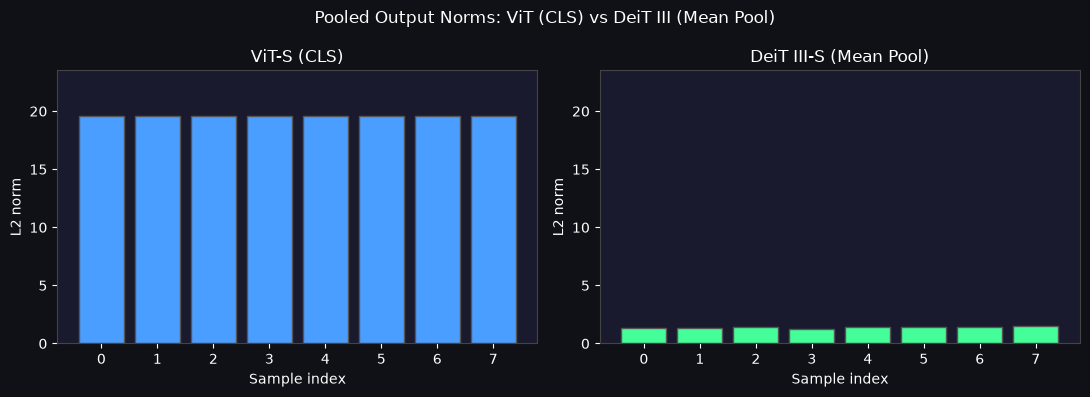

Random input — both at init, so norms are similar.
With trained weights, DeiT III mean pool tends to produce more uniform norms.


In [21]:
import sys

import torch
import numpy as np
import matplotlib.pyplot as plt

backbone = build_vision_backbone('deit3_small', img_size=224, return_all_attn=True)
backbone.eval()
print(f'Parameters:  {backbone.num_parameters():,}')
print(f'Embed dim:   {backbone.embed_dim}')
print(f'Depth:       {backbone.depth}')

# Inspect initial LayerScale gamma values
block0 = backbone.blocks[0]
print(f'\nBlock 0 - ls1 gamma[:5]: {block0.ls1.gamma[:5].detach().numpy()}')
print(f'Block 0 - ls2 gamma[:5]: {block0.ls2.gamma[:5].detach().numpy()}')
print(f'(All values = 1e-6 at init — near zero residuals)')

x = torch.randn(1, 3, 224, 224)
with torch.no_grad():
    out = backbone(x)

print(f'\npooled_output:  {out.pooled_output.shape}')   # [1, 384]
print(f'patch_tokens:   {out.patch_tokens.shape}')      # [1, 196, 384]
print(f'feature_maps:   {out.feature_maps[0].shape}')   # [1, 384, 14, 14]

# Compare ViT CLS vs DeiT III mean-pool embedding norms
vit = build_vision_backbone('vit_small', img_size=224)
vit.eval()

rng = np.random.default_rng(0)
x_batch = torch.randn(8, 3, 224, 224)
with torch.no_grad():
    out_vit   = vit(x_batch)
    out_deit3 = backbone(x_batch)

vit_pooled_norms   = out_vit.pooled_output.norm(dim=-1).numpy()
deit3_pooled_norms = out_deit3.pooled_output.norm(dim=-1).numpy()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
fig.patch.set_facecolor('#0f1117')
fig.suptitle('Pooled Output Norms: ViT (CLS) vs DeiT III (Mean Pool)', color='white', fontsize=12)

for ax, norms, name, color in zip(axes,
                                    [vit_pooled_norms, deit3_pooled_norms],
                                    ['ViT-S (CLS)', 'DeiT III-S (Mean Pool)'],
                                    ['#4a9eff', '#44ff99']):
    ax.set_facecolor('#1a1a2e')
    ax.bar(range(8), norms, color=color, edgecolor='#555')
    ax.set_title(name, color='white')
    ax.set_xlabel('Sample index', color='white')
    ax.set_ylabel('L2 norm', color='white')
    ax.tick_params(colors='white')
    ax.set_ylim(0, max(max(vit_pooled_norms), max(deit3_pooled_norms)) * 1.2)
    for sp in ax.spines.values():
        sp.set_edgecolor('#444')

plt.tight_layout()

plt.show()
print('Random input — both at init, so norms are similar.')
print('With trained weights, DeiT III mean pool tends to produce more uniform norms.')

## References

### Primary
1. H. Touvron, M. Cord, and H. Jégou, "DeiT III: Revenge of the ViT," *ECCV 2022*. [arXiv:2204.07118](https://arxiv.org/abs/2204.07118)
2. H. Touvron et al., "Going Deeper with Image Transformers," *ICCV 2021*. [arXiv:2103.17239](https://arxiv.org/abs/2103.17239) — CaiT (LayerScale origin)

### Related Works
3. H. Touvron et al., "Training data-efficient image transformers & distillation through attention," *ICML 2021*. [arXiv:2012.12877](https://arxiv.org/abs/2012.12877) — DeiT I (distillation token)
4. A. Dosovitskiy et al., "An Image is Worth 16×16 Words," *ICLR 2021*. [arXiv:2010.11929](https://arxiv.org/abs/2010.11929)
5. M. Oquab et al., "DINOv2: Learning Robust Visual Features without Supervision," *TMLR 2024*. [arXiv:2304.07193](https://arxiv.org/abs/2304.07193)
6. E. D. Cubuk et al., "RandAugment: Practical Automated Data Augmentation," *NeurIPS 2020*. [arXiv:1909.13719](https://arxiv.org/abs/1909.13719)
7. S. Yun et al., "CutMix: Training Strategy that Makes Better Use of Training Batches," *ICCV 2019*. [arXiv:1905.04899](https://arxiv.org/abs/1905.04899)